In [ ]:
# for eyepacs dataset

In [14]:
import os
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [15]:
#Configure paths and GPU
ROOT = Path("/kaggle/input/datasets/maddivenkatasuresh/eyepacs-224")
IMAGE_DIR = ROOT / "eyepacs_224" / "data"
LABELS_PATH = ROOT / "trainLabels.csv"

OUTPUT_DIR = Path("/kaggle/working/eyepacs_ben_graham_224")
OUTPUT_IMAGES = OUTPUT_DIR / "images"
OUTPUT_LABELS = OUTPUT_DIR / "trainLabels.csv"

OUTPUT_IMAGES.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 64
NUM_WORKERS = 4
SAVE_WORKERS = 4

KERNEL_SIZE = 21
SIGMA = 5.0
CONSTANT = 128.0

print("Device:", DEVICE)

if DEVICE.type != "cuda":
    raise RuntimeError("Enable GPU in Kaggle Notebook settings.")

print("GPU:", torch.cuda.get_device_name(0))
print("CPU loading workers:", NUM_WORKERS)
print("JPEG saving workers:", SAVE_WORKERS)

if not IMAGE_DIR.exists():
    raise FileNotFoundError(IMAGE_DIR)

if not LABELS_PATH.exists():
    raise FileNotFoundError(LABELS_PATH)

Device: cuda
GPU: Tesla T4
CPU loading workers: 4
JPEG saving workers: 4


In [16]:
# Load labels and match images
df = pd.read_csv(LABELS_PATH)

if not {"image", "level"}.issubset(df.columns):
    raise ValueError(f"Unexpected columns: {df.columns.tolist()}")

if df["image"].duplicated().any():
    raise ValueError("Duplicate image IDs found.")

image_map = {
    p.stem: p
    for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

records = []
missing = []

for row in df.itertuples(index=False):
    image_id = Path(str(row.image).strip()).stem
    source_path = image_map.get(image_id)

    if source_path is None:
        missing.append(image_id)
    else:
        records.append((image_id, source_path, int(row.level)))

print("Label rows:", len(df))
print("Matched images:", len(records))
print("Missing images:", len(missing))

if not records:
    raise RuntimeError("No images matched the label CSV.")

Label rows: 35126
Matched images: 35126
Missing images: 0


In [17]:
# Create the dataset and DataLoader
class FundusDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        image_id, image_path, label = self.records[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

            if image.size != (224, 224):
                raise ValueError(
                    f"{image_path.name} has size {image.size}"
                )

            array = np.asarray(image, dtype=np.uint8).copy()

        tensor = torch.from_numpy(array).permute(2, 0, 1)

        return tensor, image_id, label


loader = DataLoader(
    FundusDataset(records),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

print("DataLoader workers:", loader.num_workers)
print("Batch size:", BATCH_SIZE)
print("Number of batches:", len(loader))

DataLoader workers: 4
Batch size: 64
Number of batches: 549


In [18]:
#Create the Gaussian kernel on the GPU
coords = torch.arange(
    KERNEL_SIZE,
    device=DEVICE,
    dtype=torch.float32
) - (KERNEL_SIZE - 1) / 2

gaussian_1d = torch.exp(
    -(coords ** 2) / (2 * SIGMA ** 2)
)

gaussian_1d /= gaussian_1d.sum()

kernel = torch.outer(gaussian_1d, gaussian_1d)

kernel = kernel.view(1, 1, KERNEL_SIZE, KERNEL_SIZE)
kernel = kernel.repeat(3, 1, 1, 1)

print("Gaussian kernel shape:", kernel.shape)
print("Kernel device:", kernel.device)

Gaussian kernel shape: torch.Size([3, 1, 21, 21])
Kernel device: cuda:0


In [19]:
# Define parallel image saving
def save_image(image_id, array):
    output_path = OUTPUT_IMAGES / f"{image_id}.jpg"

    Image.fromarray(array).save(
        output_path,
        format="JPEG",
        quality=95
    )

    return image_id

In [20]:
#Perform GPU preprocessing with parallel saving
processed_count = 0
save_errors = []

torch.cuda.reset_peak_memory_stats()

with ThreadPoolExecutor(max_workers=SAVE_WORKERS) as saver:
    with torch.inference_mode():
        for pixels, image_ids, labels in tqdm(
            loader,
            desc="EyePACS GPU preprocessing"
        ):
            # Transfer batch from CPU to GPU
            x = pixels.to(DEVICE, non_blocking=True).float()

            # Gaussian blur on GPU
            pad = KERNEL_SIZE // 2

            padded = F.pad(
                x,
                (pad, pad, pad, pad),
                mode="reflect"
            )

            blurred = F.conv2d(
                padded,
                kernel,
                groups=3
            )

            # Subtract blur and adjust intensity
            result = torch.clamp(
                x - blurred + CONSTANT,
                min=0,
                max=255
            )

            # Transfer result back to CPU for JPEG saving
            arrays = (
                result.round()
                .byte()
                .cpu()
                .permute(0, 2, 3, 1)
                .numpy()
            )

            # Save images concurrently
            futures = [
                saver.submit(
                    save_image,
                    image_id,
                    arrays[i].copy()
                )
                for i, image_id in enumerate(image_ids)
            ]

            for future in as_completed(futures):
                try:
                    future.result()
                    processed_count += 1
                except Exception as exc:
                    save_errors.append(str(exc))

print("Successfully saved:", processed_count)
print("Saving errors:", len(save_errors))

if save_errors:
    print("First errors:", save_errors[:5])

EyePACS GPU preprocessing:   0%|          | 0/549 [00:00<?, ?it/s]

Successfully saved: 35126
Saving errors: 0


In [21]:
# Save labels and validate results
output_df = pd.DataFrame(
    [(image_id, label) for image_id, _, label in records],
    columns=["image", "level"]
)

output_df.to_csv(OUTPUT_LABELS, index=False)

print("\n========== PREPROCESSING REPORT ==========")
print("GPU:", torch.cuda.get_device_name(0))
print("Original label rows:", len(df))
print("Matched images:", len(records))
print("Successfully saved:", processed_count)
print("Missing image IDs:", len(missing))
print("Saving errors:", len(save_errors))
print("Output directory:", OUTPUT_DIR)
print("Output labels:", OUTPUT_LABELS)

print("\nClass distribution:")
print(output_df["level"].value_counts().sort_index())

print(
    "\nPeak GPU memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)

# Inspect a sample output
if processed_count > 0:
    sample_path = next(OUTPUT_IMAGES.glob("*.jpg"))

    with Image.open(sample_path) as sample:
        print("\nSample output:", sample_path.name)
        print("Dimensions:", sample.size)
        print("Mode:", sample.mode)

if (
    processed_count == len(records)
    and not missing
    and not save_errors
):
    print("\nSUCCESS: All matched images were processed and saved.")
else:
    print("\nWARNING: Check the report before training.")


========== PREPROCESSING REPORT ==========
GPU: Tesla T4
Original label rows: 35126
Matched images: 35126
Successfully saved: 35126
Missing image IDs: 0
Saving errors: 0
Output directory: /kaggle/working/eyepacs_ben_graham_224
Output labels: /kaggle/working/eyepacs_ben_graham_224/trainLabels.csv

Class distribution:
level
0    25810
1     2443
2     5292
3      873
4      708
Name: count, dtype: int64

Peak GPU memory: 0.22 GB

Sample output: 13704_left.jpg
Dimensions: (224, 224)
Mode: RGB

SUCCESS: All matched images were processed and saved.


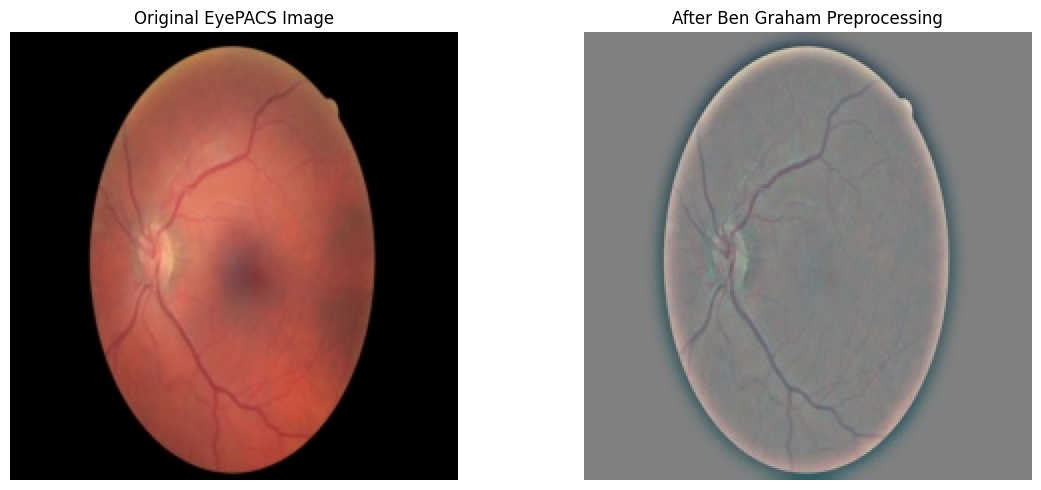

In [22]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Paths
original_path = (
    Path("/kaggle/input/datasets/maddivenkatasuresh/eyepacs-224")
    / "eyepacs_224" / "data" / "13704_left.jpg"
)

processed_path = (
    Path("/kaggle/working/eyepacs_ben_graham_224")
    / "images" / "13704_left.jpg"
)

# Load images
with Image.open(original_path) as img:
    original = img.convert("RGB").copy()

with Image.open(processed_path) as img:
    processed = img.convert("RGB").copy()

# Display side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(original)
axes[0].set_title("Original EyePACS Image")
axes[0].axis("off")

axes[1].imshow(processed)
axes[1].set_title("After Ben Graham Preprocessing")
axes[1].axis("off")

plt.tight_layout()
plt.show()

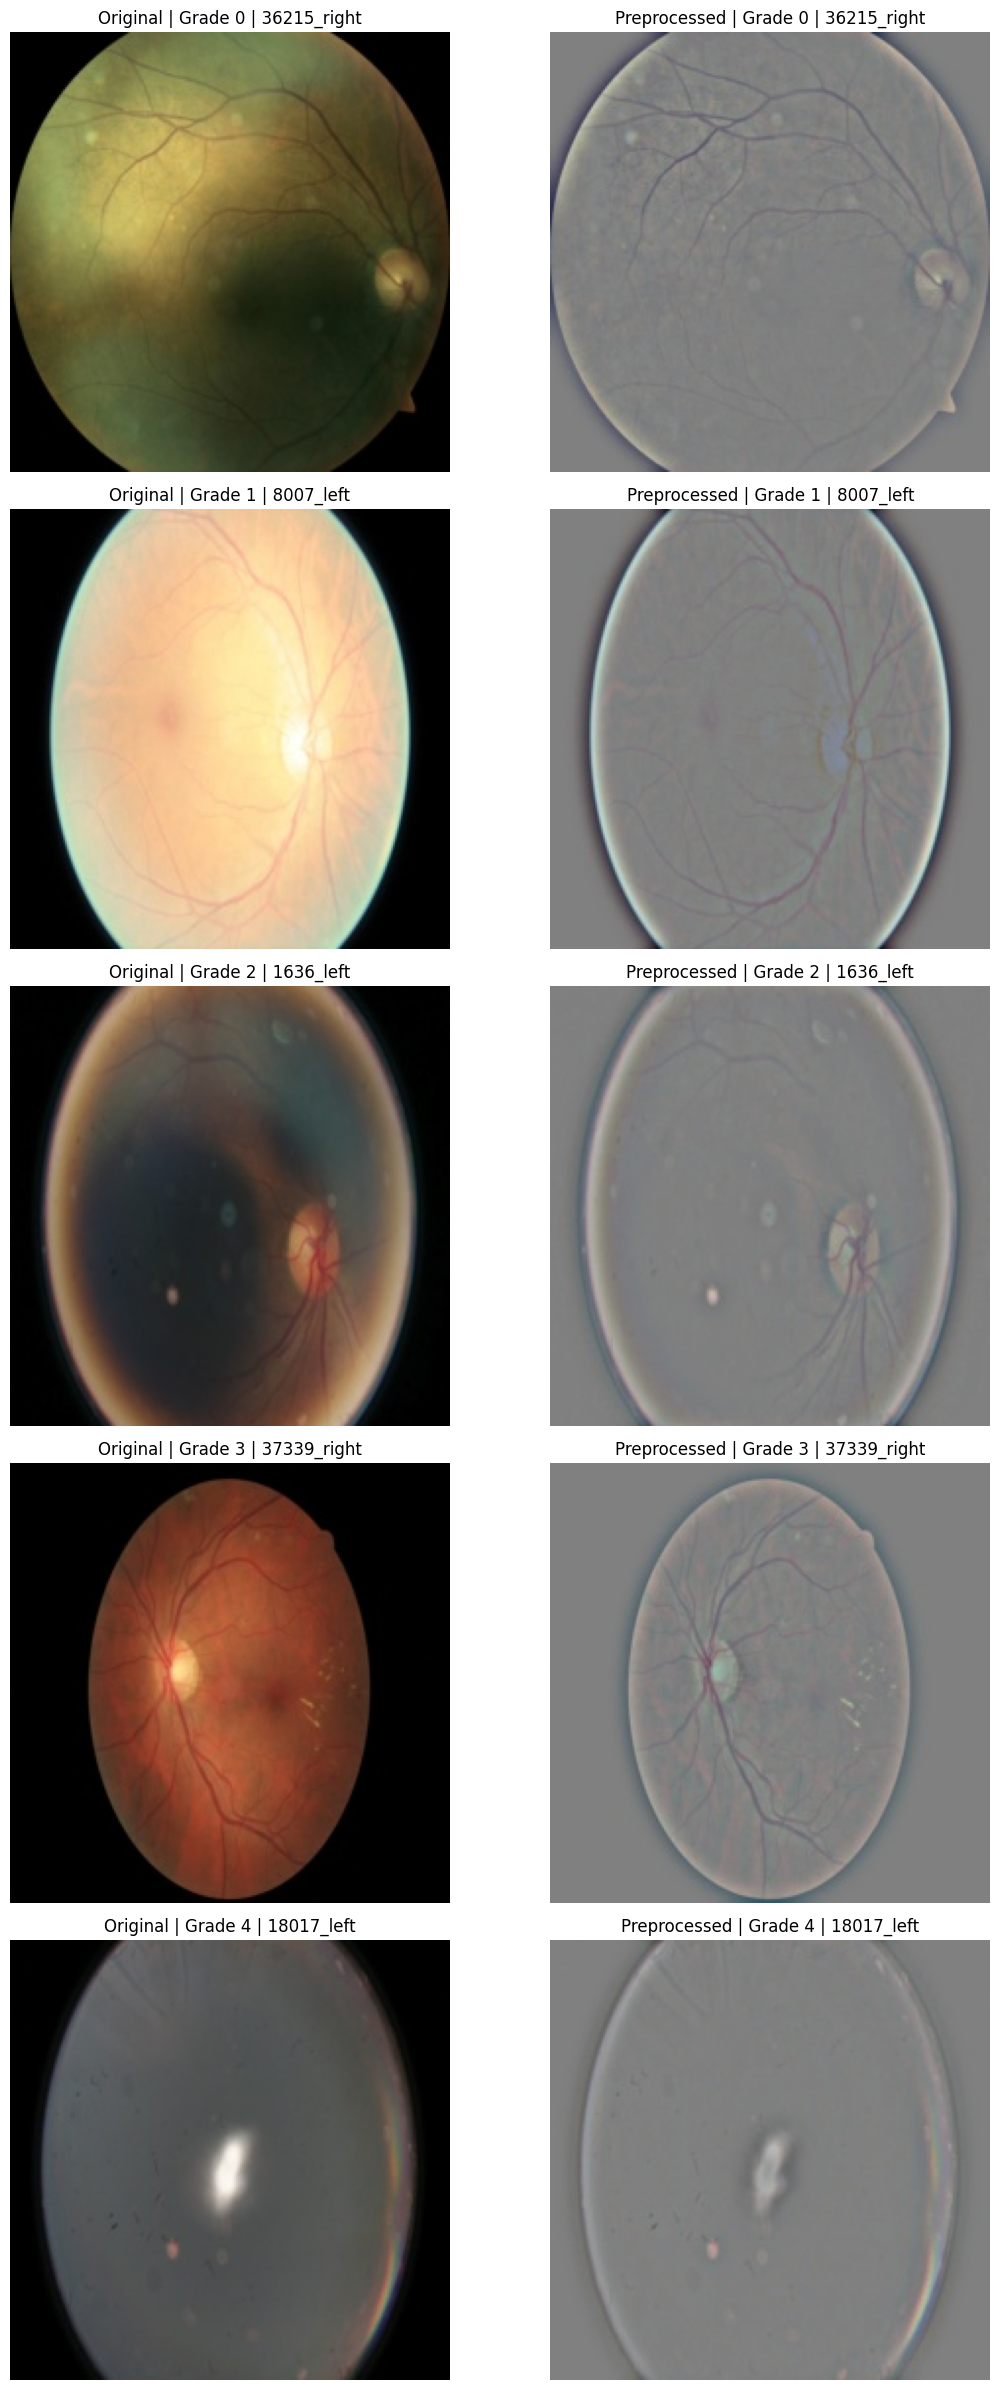

In [23]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Dataset paths
DATASET_DIR = Path("/kaggle/input/datasets/maddivenkatasuresh/eyepacs-224")
ORIGINAL_DIR = DATASET_DIR / "eyepacs_224" / "data"

PROCESSED_DIR = Path(
    "/kaggle/working/eyepacs_ben_graham_224/images"
)
LABELS_PATH = Path(
    "/kaggle/working/eyepacs_ben_graham_224/trainLabels.csv"
)

# Load labels
labels = pd.read_csv(LABELS_PATH)

# Reproducible random selection
random.seed(42)

fig, axes = plt.subplots(5, 2, figsize=(12, 24))

for grade in range(5):
    grade_df = labels[labels["level"] == grade]

    # Select an image that exists in both directories
    candidates = [
        image_id
        for image_id in grade_df["image"].astype(str)
        if (ORIGINAL_DIR / f"{image_id}.jpg").exists()
        and (PROCESSED_DIR / f"{image_id}.jpg").exists()
    ]

    if not candidates:
        print(f"No matching images found for grade {grade}")
        axes[grade, 0].axis("off")
        axes[grade, 1].axis("off")
        continue

    image_id = random.choice(candidates)

    original_path = ORIGINAL_DIR / f"{image_id}.jpg"
    processed_path = PROCESSED_DIR / f"{image_id}.jpg"

    with Image.open(original_path) as img:
        original = img.convert("RGB").copy()

    with Image.open(processed_path) as img:
        processed = img.convert("RGB").copy()

    axes[grade, 0].imshow(original)
    axes[grade, 0].set_title(
        f"Original | Grade {grade} | {image_id}"
    )
    axes[grade, 0].axis("off")

    axes[grade, 1].imshow(processed)
    axes[grade, 1].set_title(
        f"Preprocessed | Grade {grade} | {image_id}"
    )
    axes[grade, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# for aptos dataset 

In [30]:

import os
import math
import random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 4
KERNEL_SIZE = 21
SIGMA = 5.0
CONSTANT = 128.0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert torch.cuda.is_available(), "Enable GPU in Kaggle Settings!"

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# 2. Automatically locate the APTOS training CSV
# --------------------------------------------------
input_root = Path("/kaggle/input")

csv_candidates = [
    p for p in input_root.rglob("train.csv")
    if "aptos" in str(p).lower()
]

if not csv_candidates:
    raise FileNotFoundError(
        "Could not find APTOS train.csv under /kaggle/input. "
        "Check your attached dataset and CSV filename."
    )

csv_path = csv_candidates[0]
dataset_root = csv_path.parent
labels = pd.read_csv(csv_path)

if not {"id_code", "diagnosis"}.issubset(labels.columns):
    raise ValueError(
        f"Expected columns id_code and diagnosis; found {list(labels.columns)}"
    )

print("CSV:", csv_path)
print("Rows:", len(labels))
print("Class distribution:")
print(labels["diagnosis"].value_counts().sort_index())

# --------------------------------------------------
# 3. Locate images recursively
# --------------------------------------------------
valid_extensions = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

image_map = {}
for p in dataset_root.rglob("*"):
    if p.is_file() and p.suffix.lower() in valid_extensions:
        image_map.setdefault(p.stem, p)

# Match IDs from the CSV to their actual image files
records = []
missing = []

for _, row in labels.iterrows():
    image_id = str(row["id_code"])
    image_path = image_map.get(image_id)

    if image_path is None:
        missing.append(image_id)
    else:
        records.append({
            "id_code": image_id,
            "diagnosis": int(row["diagnosis"]),
            "path": str(image_path),
        })

if missing:
    print("Missing images:", len(missing))
    print("Examples:", missing[:10])

if not records:
    raise RuntimeError("No APTOS images matched the labels CSV.")

print("Matched images:", len(records))

# --------------------------------------------------
# 4. Dataset and image loading
# --------------------------------------------------
class APTOSDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        with Image.open(record["path"]) as img:
            img = img.convert("RGB").resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                Image.Resampling.LANCZOS
            )
            arr = np.asarray(img, dtype=np.float32).copy()

        tensor = torch.from_numpy(arr).permute(2, 0, 1)
        return tensor, record["id_code"]

dataset = APTOSDataset(records)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)

# --------------------------------------------------
# 5. Create Gaussian blur kernel on GPU
# --------------------------------------------------
coords = torch.arange(
    KERNEL_SIZE, device=device, dtype=torch.float32
) - (KERNEL_SIZE - 1) / 2

gaussian_1d = torch.exp(
    -(coords ** 2) / (2 * SIGMA ** 2)
)
gaussian_1d /= gaussian_1d.sum()

gaussian_2d = torch.outer(gaussian_1d, gaussian_1d)
gaussian_2d /= gaussian_2d.sum()

kernel = gaussian_2d.view(1, 1, KERNEL_SIZE, KERNEL_SIZE)
kernel = kernel.repeat(3, 1, 1, 1).contiguous()

# --------------------------------------------------
# 6. Preprocess and save images
# --------------------------------------------------
output_dir = Path("/kaggle/working/aptos_ben_graham_224")
output_images = output_dir / "images"
output_images.mkdir(parents=True, exist_ok=True)

def save_image(image_array, image_id):
    Image.fromarray(image_array).save(
        output_images / f"{image_id}.png",
        format="PNG",
        optimize=False,
    )

save_pool = ThreadPoolExecutor(max_workers=NUM_WORKERS)
save_futures = []
processed = 0

try:
    for batch, image_ids in tqdm(loader, desc="APTOS preprocessing"):
        batch = batch.to(device, non_blocking=True)

        # Scale RGB values to [0, 1]
        batch = batch / 255.0

        # Reflect padding reduces artificial edge effects
        pad = KERNEL_SIZE // 2
        padded = F.pad(
            batch,
            (pad, pad, pad, pad),
            mode="reflect",
        )

        # Per-channel Gaussian blur
        blurred = F.conv2d(
            padded,
            kernel,
            groups=3,
        )

        # Ben Graham-style local contrast enhancement
        enhanced = batch - blurred + (CONSTANT / 255.0)
        enhanced = enhanced.clamp(0.0, 1.0)

        # Convert back to uint8 on CPU
        enhanced = (
            enhanced.mul(255.0)
            .round()
            .to(torch.uint8)
            .cpu()
            .permute(0, 2, 3, 1)
            .numpy()
        )

        for arr, image_id in zip(enhanced, image_ids):
            save_futures.append(
                save_pool.submit(save_image, arr, image_id)
            )

        processed += len(image_ids)

    for future in tqdm(save_futures, desc="Saving images"):
        future.result()

finally:
    save_pool.shutdown(wait=True)

# --------------------------------------------------
# 7. Save matching labels
# --------------------------------------------------
output_labels = pd.DataFrame([
    {
        "id_code": r["id_code"],
        "diagnosis": r["diagnosis"],
    }
    for r in records
])

output_labels.to_csv(
    output_dir / "train.csv",
    index=False,
)

# --------------------------------------------------
# 8. Verify output
# --------------------------------------------------
saved_count = len(list(output_images.glob("*.png")))

print("\nPreprocessing completed!")
print("Images processed:", processed)
print("Images saved:", saved_count)
print("Labels saved:", len(output_labels))
print("Output directory:", output_dir)
print("GPU peak memory: %.2f GB" % (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
))

assert saved_count == len(records), (
    "Saved image count does not match matched input count!"
)


GPU: Tesla T4
CSV: /kaggle/input/datasets/maddivenkatasuresh/aptos-224/aptos_data/train.csv
Rows: 3662
Class distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64
Matched images: 3662


APTOS preprocessing:   0%|          | 0/58 [00:00<?, ?it/s]

Saving images:   0%|          | 0/3662 [00:00<?, ?it/s]


Preprocessing completed!
Images processed: 3662
Images saved: 3662
Labels saved: 3662
Output directory: /kaggle/working/aptos_ben_graham_224
GPU peak memory: 0.28 GB


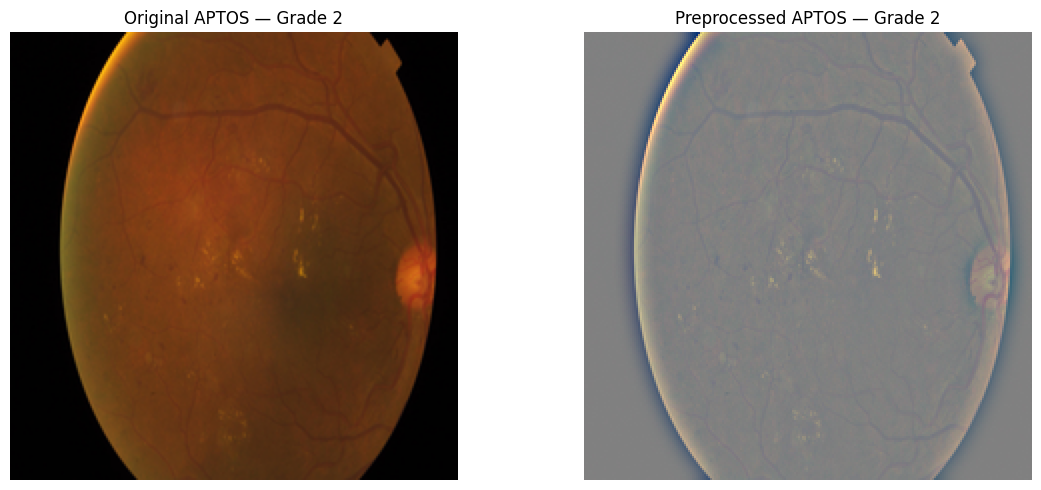

In [31]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("/kaggle/working/aptos_ben_graham_224")
labels = pd.read_csv(output_dir / "train.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

image_id = labels.iloc[0]["id_code"]
grade = labels.iloc[0]["diagnosis"]

original_path = image_map[image_id]
processed_path = output_dir / "images" / f"{image_id}.png"

with Image.open(original_path) as img:
    axes[0].imshow(img.convert("RGB"))
axes[0].set_title(f"Original APTOS — Grade {grade}")
axes[0].axis("off")

with Image.open(processed_path) as img:
    axes[1].imshow(img.convert("RGB"))
axes[1].set_title(f"Preprocessed APTOS — Grade {grade}")
axes[1].axis("off")

plt.tight_layout()
plt.show()